In [149]:
import sys
from typing import List, Tuple
import pickle as pkl

import matplotlib.pyplot as plt; plt.rcParams.update({"font.family": "serif"})
import numpy as np
import scipy as sp

import openfermion as of
from openfermionpyscf import run_pyscf

import numpy as np
import openfermion as of

import cirq
import qiskit
import qiskit.qasm2
import quimb.tensor as qtn

sys.path.append("..")
from tensor_network_common import pauli_sum_to_mpo

In [150]:
# Problem to use.
problem: str = "product"  # Options: "hchain", "hubbard", "product", "reactant"

# For Hubbard Hamiltonian.
xdim: int = 4
ydim: int = 3

# For Hydrogen chains.
natoms: int = 3  # Number of H atoms in the (linear) chain.

hamiltonian_threshold: float = 0.02 # Drop terms in the Hamiltonian with coefficients smaller than this threshold.

# Initial state parameters.
seed: int = 1
alpha: float = 10.0  # The initial state is |ground state> + |random state> / alpha.

# Krylov parameters.
subspace_dimension: int = 20  # The dimension of the Krylov subspace.
threshold: float = 1e-4 # 1e-4  # -np.inf  # -1e-4  # Set to -np.inf to disable thresholding.

# Simulation parameters.
max_mpo_bond: int = 128  # Maximum bond dimension for MPO's.
max_mps_bond: int = 256  # Maximum bond dimension for MPS's.

In [151]:
def fill_h_and_s_matrices(
    vectors: List[np.ndarray] | List[np.ndarray],
    mpo: qtn.MatrixProductOperator | np.ndarray,
    verbose: bool = False,
) -> Tuple[np.ndarray, np.ndarray]:
    tensor_algebra = isinstance(mpo, qtn.MatrixProductOperator)

    dim = len(vectors)
    h = np.zeros((dim, dim), dtype=np.complex128)
    s = np.zeros((dim, dim), dtype=np.complex128)

    for i in range(dim):
        for j in range(i, dim):
            if verbose:
                print(f"A_{i}{j}", end=" ")

            if tensor_algebra:
                hij = vectors[i].H @ mpo.apply(vectors[j])
            else:
                hij = vectors[i].conj().T @ mpo @ vectors[j]

            h[i, j] = hij
            if i != j:
                h[j, i] = np.conjugate(hij)

            if tensor_algebra:
                sij = vectors[i].H @ vectors[j]
            else:
                sij = vectors[i].conj().T @ vectors[j]
            s[i, j] = sij
            if i != j:
                s[j, i] = np.conjugate(sij)
    return h, s

# Based on https://quantum.cloud.ibm.com/docs/en/tutorials/krylov-quantum-diagonalization.
# and Algorithm 1.1 of https://arxiv.org/abs/2110.07492.
def solve_regularized_gen_eig(
    h: np.ndarray,
    s: np.ndarray,
    threshold: float = -np.inf,
) -> float:
    s_vals, s_vecs = sp.linalg.eigh(s)
    s_vecs = s_vecs.T
    good_vecs = np.array(
        [vec for val, vec in zip(s_vals, s_vecs) if val > threshold]
    )
    h_reg = good_vecs.conj() @ h @ good_vecs.T
    s_reg = good_vecs.conj() @ s @ good_vecs.T
    return sp.linalg.eigh(h_reg, s_reg)[0][0]

In [152]:
def cirq_pauli_sum_to_qiskit_pauli_op(pauli_sum: cirq.PauliSum) -> qiskit.quantum_info.SparsePauliOp:
    """Returns a qiskit.SparsePauliOp representation of the cirq.PauliSum."""
    cirq_pauli_to_str = {cirq.X: "X", cirq.Y: "Y", cirq.Z: "Z"}

    qubits = pauli_sum.qubits
    terms = []
    coeffs = []
    for term in pauli_sum:
        string = ""
        for qubit in qubits:
            if qubit not in term:
                string += "I"
            else:
                string += cirq_pauli_to_str[term[qubit]]
        terms.append(string)
        assert np.isclose(term.coefficient.imag, 0.0, atol=1e-7)
        coeffs.append(term.coefficient.real)
    return qiskit.quantum_info.SparsePauliOp(terms, coeffs)

In [153]:
def unitary_h_and_s_variance(
    vectors: List[np.ndarray] | List[np.ndarray], ks: List[int], mpo: qtn.MatrixProductOperator | np.ndarray,
    subspace_dimension: int,
    h: np.ndarray, s: np.ndarray
) -> Tuple[np.ndarray, np.ndarray]:
    """Compute the variance of the real and imaginary parts of the matrix elements
    H_ij and S_ij. When using the IBM measurement technique, the expectation values of
    X otimes H and Y otimes H give us the real and imaginary parts of the matrix
    elements. So to find the variance of H_ij, we would use 
    <(X otimes H)^2> = <(Y otimes H)^2> = <(I otimes H^2)>. 
    The value is
    <(I otimes H^2)> = 1/2 (<psi0| H^2 |psi0> + <psi0|U_{k-j}^dag H^2 U_{k-j}|psi0>).
    For the variance of S_ij, we would set H=I, giving
    <(I otimes I)> = 1/2 (<psi0|psi0> + <psi0|U_{k-j}^dag U_{k-j}|psi0>) = <psi0|psi0> = 1.
    
    Arguments:
    vectors - The vectors spanning the subspace.
    ks - The power of the unitary generating each vector, e.g. k=2 for U^2|psi_0>.
    Negative values mean backwards time evolution, i.e. powers of U^dagger.
    mpo - Hamiltonian operator.
    h - H matrix previously calculated.
    s - S matrix previously calculated.
    
    Returns:
    h_var - The re/im of h_var[i, j] is the variance of the re/im of H_ij.
    s_var - The re/im of s_var[i, j] is the variance of the re/im of S_ij."""

    assert len(ks) == len(vectors)

    tensor_algebra = isinstance(mpo, qtn.MatrixProductOperator)

    dim = len(vectors)
    h_var = np.zeros((subspace_dimension+1, subspace_dimension+1), dtype=np.complex128)
    s_var = np.zeros((subspace_dimension+1, subspace_dimension+1), dtype=np.complex128)

    # Find the reference state to get <psi0|H^2|psi0>.
    idx = ks.index(0)
    psi0 = vectors[idx]
    if tensor_algebra:
        psi0_h2_psi0 = psi0.H @ mpo.apply(mpo.apply(psi0))
    else:
        psi0_h2_psi0 = psi0.conj().T @ mpo @ mpo @ psi0
    
    for k in range(-subspace_dimension // 2, subspace_dimension // 2 + 1, 1):
        for j in range(-subspace_dimension // 2, subspace_dimension // 2 + 1, 1):
            # print(f"k={k} j={j}, k-j={k-j}")
            # Find a state with power k-j. Compute <psi0|U^dag_{k-j} H^2 U_{k-j}|psi0>.
            idx = ks.index(k - j)
            if tensor_algebra:
                psi0_u_h2_u_psi0 = vectors[idx].H @ mpo.apply(mpo.apply(vectors[idx]))
            else:
                psi0_u_h2_u_psi0 = vectors[idx].conj().T @ mpo @ mpo @ vectors[idx]
            exp_h_sq = 0.5 * (psi0_h2_psi0 + psi0_u_h2_u_psi0)
            var_re_h_kj = exp_h_sq - h[k, j].real ** 2
            var_im_h_kj = exp_h_sq - h[k, j].real ** 2
            h_var[k, j] = var_re_h_kj + 1.0j * var_im_h_kj
            var_re_s_kj = 1. - s[k, j].real ** 2
            var_im_s_kj = 1. - s[k, j].real ** 2
            h_var[k, j] = var_re_s_kj + 1.0j * var_im_s_kj

    return h_var, s_var

In [154]:
def perturb_h_s_with_noise(h: np.ndarray, s: np.ndarray, h_var: np.ndarray, s_var: np.ndarray, shots: int):
    assert h.shape == h_var.shape, f"{h.shape} != {h_var.shape}"
    assert s.shape == s_var.shape, f"{s.shape} != {s_var.shape}"

    noisy_h = np.zeros(h.shape).astype(complex)
    noisy_s = np.zeros(s.shape).astype(complex)

    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            if h_var[i, j].real < 0.:
                if abs(h_var[i, j].real) <= 1e-8:
                    h_var_real = 0.
                else:
                    raise ValueError(f"{h_var[i, j].real}")
            else:
                h_var_real = h_var[i, j].real
            if h_var[i, j].imag < 0.:
                if abs(h_var[i, j].imag) <= 1e-8:
                    h_var_imag = 0.
                else:
                    raise ValueError(f"{h_var[i, j].imag}")
            else:
                h_var_imag = h_var[i, j].imag
            std_re_hij = np.sqrt(h_var_real / shots)
            std_im_hij = np.sqrt(h_var_imag / shots)
            noise = np.random.normal(scale=std_re_hij) + 1.j * np.random.normal(scale=std_im_hij)
            assert not np.isnan(noise), f"{h_var[i, j]} {noise}"
            noisy_h[i, j] = h[i, j] + noise

            if s_var[i, j].real < 0.:
                if abs(s_var[i, j].real) <= 1e-8:
                    s_var_real = 0.
                else:
                    raise ValueError(f"{s_var[i, j].real}")
            else:
                s_var_real = s_var[i, j].real
            if s_var[i, j].imag < 0.:
                if abs(s_var[i, j].imag) <= 1e-8:
                    s_var_imag = 0.
                else:
                    raise ValueError(f"{s_var[i, j].imag}")
            else:
                s_var_imag = s_var[i, j].imag
            std_re_sij = np.sqrt(s_var_real / shots)
            std_im_sij = np.sqrt(s_var_imag / shots)
            noise = np.random.normal(scale=std_re_sij) + 1.j * np.random.normal(scale=std_im_sij)
            assert not np.isnan(noise), f"{s_var[i, j]} {s_var_real} {s_var_imag} {noise}"
            noisy_s[i, j] = s[i, j] + noise
    
    assert not np.any(np.isnan(noisy_h))
    assert not np.any(np.isnan(noisy_s))
    return noisy_h, noisy_s

In [156]:
def hchain_matrices(natoms: int, subspace_dimension: int, ntrotter: int=1):
    bond_distance = 1.0
    geometry = [("H", (0, 0, i * bond_distance)) for i in range(natoms)]
    molecule = of.MolecularData(geometry, basis="sto-3g", multiplicity=1, charge=natoms % 2)

    molecule = run_pyscf(molecule, run_scf=True, run_mp2=True, verbose=True)

    hamiltonian = of.get_fermion_operator(molecule.get_molecular_hamiltonian())
    hamiltonian = of.jordan_wigner(hamiltonian)
    if hamiltonian_threshold is not None:
        hamiltonian.compress(hamiltonian_threshold)
    nqubits = of.utils.count_qubits(hamiltonian)
    nterms = len(hamiltonian.terms)

    # Get the exact ground state.
    hamiltonian_cirq = of.qubit_operator_to_pauli_sum(hamiltonian)
    mpo = pauli_sum_to_mpo(hamiltonian_cirq, cirq.LineQubit.range(nqubits), max_bond=max_mpo_bond, verbose=False)
    dmrg = qtn.DMRG2(mpo, bond_dims=[2 ** (i + 1) for i in range(int(np.log2(max_mpo_bond)))])
    dmrg.solve(verbosity=1)

    energy_exact = np.real(dmrg.energy)
    ground_state = dmrg.state

    bvec = ground_state + qtn.MPS_rand_state(mpo.L, bond_dim=2, seed=seed) / alpha
    bvec /= bvec.norm()


    dt = np.pi / mpo.norm()
    dt *= 5 * natoms  # Empirically found that larger dt works better for H chains.

    hamiltonian_qiskit = cirq_pauli_sum_to_qiskit_pauli_op(hamiltonian_cirq)
    trotter_operation = qiskit.circuit.library.PauliEvolutionGate(
        hamiltonian_qiskit,
        time=dt,
        synthesis=qiskit.synthesis.LieTrotter(reps=ntrotter)
    )
    trotter_circuit = qiskit.QuantumCircuit(nqubits)
    trotter_circuit.append(trotter_operation, trotter_circuit.qubits)
    trotter_circuit = qiskit.transpile(
        trotter_circuit, basis_gates=["u3", "cx"]
    )  # TODO: Compile to a target backend, e.g. IBM Fez.
    # print("Trotter circuit gate counts:")
    # print(trotter_circuit.count_ops())

    # trotter_circuits.append(trotter_circuit)

    forward = trotter_circuit.copy()
    forward_qasm = qiskit.qasm2.dumps(forward)

    reverse = trotter_circuit.inverse().copy()
    reverse_qasm = qiskit.qasm2.dumps(reverse)

    forward_vectors = [bvec]

    for k in range(subspace_dimension):
        # print("Forward:", k)
        new = qtn.CircuitMPS.from_openqasm2_str(
            forward_qasm, psi0=forward_vectors[-1], progbar=False, max_bond=max_mps_bond,
        ).psi
        forward_vectors.append(new)
    
    reverse_vectors = [bvec]
    for k in range(subspace_dimension):
        # print("Reverse:", k)
        new = qtn.CircuitMPS.from_openqasm2_str(
            reverse_qasm, psi0=reverse_vectors[-1], progbar=False, max_bond=max_mps_bond,
        ).psi
        reverse_vectors.append(new)

    _ = reverse_vectors.pop(0)
    reverse_vectors = list(reversed(reverse_vectors))

    all_vectors_u_trotter = reverse_vectors + forward_vectors
    ks = list(range(-subspace_dimension, subspace_dimension + 1))

    vectors_u_trotter = []
    for k, vec in zip(ks, all_vectors_u_trotter):
        if (k >= -subspace_dimension // 2) and (k <= subspace_dimension // 2):
            vectors_u_trotter.append(vec)

    h, s = fill_h_and_s_matrices(vectors_u_trotter, mpo, verbose=False)
    h_var, s_var = unitary_h_and_s_variance(all_vectors_u_trotter, ks, mpo, subspace_dimension, h, s)
    return h, s, h_var, s_var, energy_exact

In [157]:
h, s, h_var, s_var, energy_exact = hchain_matrices(3, subspace_dimension, ntrotter=3)

Hartree-Fock energy for H3_sto-3g_singlet_1+ (2 electrons) is -1.1889970389622464.
MP2 energy for H3_sto-3g_singlet_1+ (2 electrons) is -1.2131306955585308.
1, R, max_bond=(2/2), cutoff:1e-08


100%|###########################################| 5/5 [00:00<00:00, 1742.11it/s]

Energy: (-1.5179539174683983+3.0032400177848473e-15j) ... not converged.
2, R, max_bond=(2/4), cutoff:1e-08



100%|###########################################| 5/5 [00:00<00:00, 1295.58it/s]

Energy: (-1.5452095284189422+2.654126918244515e-15j) ... not converged.
3, R, max_bond=(4/8), cutoff:1e-08



100%|###########################################| 5/5 [00:00<00:00, 1384.99it/s]

Energy: (-1.5483771453164807+2.8449465006019636e-15j) ... not converged.
4, R, max_bond=(6/16), cutoff:1e-08



100%|############################################| 5/5 [00:00<00:00, 997.55it/s]

Energy: (-1.5618170513793646+1.48318857196017e-15j) ... not converged.
5, R, max_bond=(7/32), cutoff:1e-08



100%|###########################################| 5/5 [00:00<00:00, 1171.20it/s]

Energy: (-1.5618170516202636+1.3071141391485241e-15j) ... converged!


In [158]:
nshots = np.logspace(2, 9, num=3)
reps = 10
mean_errs = []
std_errs = []
for shots in nshots:
    print(f"shots={shots}")
    noisy_energies = []
    for _ in range(reps):
        noisy_h, noisy_s = perturb_h_s_with_noise(h, s, h_var, s_var, shots)
        # print(sp.linalg.norm(noisy_h - h))
        noisy_energy = solve_regularized_gen_eig(noisy_h, noisy_s, threshold)
        noisy_energies.append(noisy_energy)
    errs = np.abs(noisy_energies - energy_exact)
    mean_errs.append(np.mean(errs))
    std_errs.append(np.std(errs))

shots=100.0
shots=316227.7660168379
shots=1000000000.0


Text(0, 0.5, 'Absolute energy error')

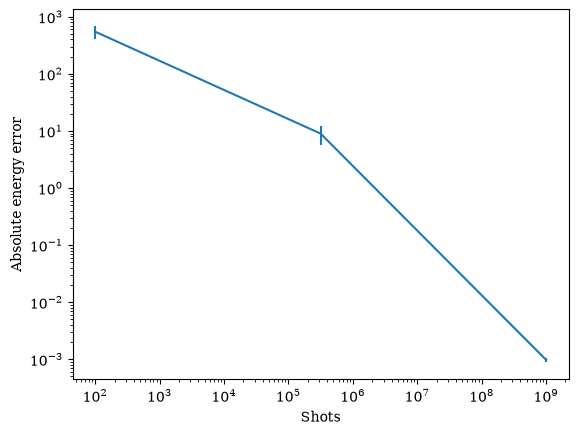

In [159]:
fig, ax = plt.subplots()
ax.errorbar(nshots, mean_errs, yerr=std_errs)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Shots")
ax.set_ylabel("Absolute energy error")